# NFL Win Prediction: Bayesian Beta-Binomial Model

Every team has an unknown probability of winning, $p$. We start with a Beta prior and update it with the team's win/loss record before the game:

This notebook builds three versions of the model and compares them on the same chronological test set:
1. **Team only:** predict a win if the team's posterior mean is above 0.5.
2. **Head-to-head:** compare the two teams' posterior means with the log5 formula.
3. **Head-to-head + home field:** add a home-field effect, itself estimated with a Beta-Binomial model on the training seasons.

Everything is computed with NumPy and plotted with Matplotlib. Records use only games played **before** each game.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from math import lgamma
from pathlib import Path

np.random.seed(42)

# Folder written by the data preparation notebook
DATA_DIR = Path("../Data/data/processed")

In [2]:
# Load the data
series = pd.read_csv(DATA_DIR / "nfl_team_game_model_data.csv")
train = pd.read_csv(DATA_DIR / "nfl_train.csv")
validation = pd.read_csv(DATA_DIR / "nfl_validation.csv")
test = pd.read_csv(DATA_DIR / "nfl_test.csv")

# Print information about the data
train_seasons = sorted(train["season"].unique().tolist())
validation_seasons = sorted(validation["season"].unique().tolist())
test_seasons = sorted(test["season"].unique().tolist())

print("Full series:", series.shape)
print("Train seasons:", train_seasons[0], "-", train_seasons[-1])
print("Validation seasons:", validation_seasons)
print("Test seasons:", test_seasons)
print("Rows (train / validation / test):", len(train), len(validation), len(test))

# Define functions to compute classification metrics and log loss
def classification_metrics(y_true, y_pred):
    """Accuracy, precision, recall, F1 and confusion matrix (computed with NumPy)."""
    y_true = np.asarray(y_true).astype(int)
    y_pred = np.asarray(y_pred).astype(int)
    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))

    accuracy = (tp + tn) / len(y_true)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
    cm = np.array([[tn, fp], [fn, tp]])   # rows = actual (loss, win), columns = predicted
    return {"accuracy": accuracy, "precision": precision, "recall": recall, "f1": f1, "confusion_matrix": cm}

def log_loss(y_true, p, eps=1e-12):
    p = np.clip(np.asarray(p, dtype=float), eps, 1 - eps)
    y = np.asarray(y_true, dtype=float)
    return float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))


def plot_confusion_matrix(cm, title):
    plt.figure(figsize=(4, 4))
    plt.imshow(cm, cmap="Blues")
    plt.xticks([0, 1], ["Pred loss", "Pred win"])
    plt.yticks([0, 1], ["Actual loss", "Actual win"])
    for i in range(2):
        for j in range(2):
            plt.text(j, i, cm[i, j], ha="center", va="center",
                     color="white" if cm[i, j] > cm.max() / 2 else "black")
    plt.title(title)
    plt.show()

Full series: (14067, 34)
Train seasons: 1999 - 2017
Validation seasons: [2018, 2019, 2020, 2021]
Test seasons: [2022, 2023, 2024, 2025, 2026]
Rows (train / validation / test): 9518 2064 2485


In [3]:
# Check: A team plays 10 games and wins 7. 
# With a uniform Beta(1, 1) prior the posterior is Beta(8, 4), with mean 8/12 = 0.667.
alpha0, beta0 = 1, 1
wins, losses = 7, 3

alpha_post, beta_post = alpha0 + wins, beta0 + losses
print(f"Posterior: Beta({alpha_post}, {beta_post})")
print(f"Posterior mean: {alpha_post / (alpha_post + beta_post):.3f}")

Posterior: Beta(8, 4)
Posterior mean: 0.667


In [4]:
# Season-to-date record and previous season's record for each team-game.
# these come from the data processing notebook, where they're counted from every game
# before any rows get dropped

series = series.sort_values(["team", "season", "week", "game_id"]).reset_index(drop=True)
series = series.rename(columns={"prev_season_wins": "prev_wins",
                                "prev_season_games": "prev_games"})

series[["season", "week", "team", "season_wins_before", "season_games_before",
        "prev_wins", "prev_games", "win"]].head(8)

,season,week,team,season_wins_before,season_games_before,prev_wins,prev_games,win
0,1999,4,ARI,1,3,0.0,0.0,0
1,1999,5,ARI,1,4,0.0,0.0,1
2,1999,6,ARI,2,5,0.0,0.0,0
3,1999,8,ARI,2,6,0.0,0.0,0
4,1999,9,ARI,2,7,0.0,0.0,0
5,1999,10,ARI,2,8,0.0,0.0,1
6,1999,11,ARI,3,9,0.0,0.0,1
7,1999,12,ARI,4,10,0.0,0.0,1


In [5]:
def score_games(df, a=1.0, carry=0.0, head_to_head=True, home_logit=0.0):
    """P(win) for every team-game row in df, using only information from before the game."""
    wins = df["season_wins_before"].to_numpy(float)
    played = df["season_games_before"].to_numpy(float)
    prev_w = df["prev_wins"].to_numpy(float)
    prev_l = (df["prev_games"] - df["prev_wins"]).to_numpy(float)

    # Posterior Beta(alpha, beta) and its mean for each team-game
    alpha = a + wins + carry * prev_w
    beta = a + (played - wins) + carry * prev_l
    p_team = alpha / (alpha + beta)

    if not head_to_head:
        prob = p_team
    else:
        # Look up the opponent's posterior mean from the same game
        p_lookup = pd.Series(p_team, index=pd.MultiIndex.from_arrays([df["game_id"], df["team"]]))
        opp_index = pd.MultiIndex.from_arrays([df["game_id"], df["opponent_team"]])
        p_opp = p_lookup.reindex(opp_index).to_numpy()

        prob = p_team * (1 - p_opp) / (p_team * (1 - p_opp) + p_opp * (1 - p_team))   # log5

        # a few games are missing the opponent's row, so just use the team's own
        # posterior mean for those (otherwise prob is NaN and the log loss is NaN)
        prob = np.where(np.isnan(p_opp), p_team, prob)

        if home_logit != 0:
            z = np.log(prob / (1 - prob)) + np.where(df["is_home"] == 1, home_logit, -home_logit)
            prob = 1 / (1 + np.exp(-z))

    return pd.DataFrame({"game_id": df["game_id"].to_numpy(),
                         "team": df["team"].to_numpy(),
                         "prob": prob})


def attach(split_df, scored):
    """Attach model probabilities to the rows of a train/validation/test file."""
    return split_df[["game_id", "team", "season", "week", "is_home", "win"]].merge(
        scored, on=["game_id", "team"], how="left", validate="one_to_one"
    )


# Home-field effect estimated from TRAINING seasons only (Beta(1,1) prior -> posterior mean)
home_rows = series[series["season"].isin(train_seasons) & (series["is_home"] == 1)]
home_wins, home_games = int(home_rows["win"].sum()), len(home_rows)
p_home = (1 + home_wins) / (2 + home_games)
home_logit = np.log(p_home / (1 - p_home))
print(f"Posterior mean home win rate (train): {p_home:.3f}  -> home_logit = {home_logit:.3f}")

Posterior mean home win rate (train): 0.572  -> home_logit = 0.290


In [6]:
# Tune hyperparameters
rows = []
for a in [0.5, 1, 2, 4, 8]:
    for carry in [0.0, 0.25, 0.5, 1.0]:
        scored = score_games(series, a=a, carry=carry, head_to_head=True, home_logit=home_logit)
        m = attach(validation, scored)
        rows.append({
            "a": a, "carry": carry,
            "val_log_loss": log_loss(m["win"], m["prob"]),
            "val_accuracy": ((m["prob"] > 0.5).astype(int) == m["win"]).mean(),
        })

tuning = pd.DataFrame(rows).sort_values("val_log_loss").reset_index(drop=True)
display(tuning.head(8))

best_a = float(tuning.loc[0, "a"])
best_carry = float(tuning.loc[0, "carry"])
print(f"Selected prior: Beta({best_a}, {best_a}) with carry = {best_carry}")

,a,carry,val_log_loss,val_accuracy
0,4.0,0.50,0.640766,0.632267
1,2.0,0.50,0.642200,0.639050
2,2.0,0.25,0.642519,0.626938
3,4.0,0.25,0.642737,0.631783
4,8.0,1.00,0.644703,0.628391
5,4.0,1.00,0.645196,0.625000
6,8.0,0.50,0.645309,0.618217
7,1.0,0.50,0.646583,0.639050


Selected prior: Beta(4.0, 4.0) with carry = 0.5


In [7]:
# Evaluate the three variants of the model on validation and test sets, using the best hyperparameters
variants = {
    "Beta-Binomial (team only)":           dict(head_to_head=False, home_logit=0.0),
    "Beta-Binomial head-to-head (log5)":   dict(head_to_head=True,  home_logit=0.0),
    "Beta-Binomial head-to-head + home":   dict(head_to_head=True,  home_logit=home_logit),
}

results = []
test_scored = {}
for name, kwargs in variants.items():
    scored = score_games(series, a=best_a, carry=best_carry, **kwargs)
    for split_name, split_df in [("validation", validation), ("test", test)]:
        m = attach(split_df, scored)
        pred = (m["prob"] > 0.5).astype(int)
        met = classification_metrics(m["win"], pred)
        results.append({"model": name, "split": split_name,
                        "accuracy": met["accuracy"], "precision": met["precision"],
                        "recall": met["recall"], "f1": met["f1"],
                        "log_loss": log_loss(m["win"], m["prob"])})
        if split_name == "test":
            test_scored[name] = m

# Baseline: always predict the home team wins
for split_name, split_df in [("validation", validation), ("test", test)]:
    met = classification_metrics(split_df["win"], split_df["is_home"])
    results.append({"model": "Baseline: always home", "split": split_name,
                    "accuracy": met["accuracy"], "precision": met["precision"],
                    "recall": met["recall"], "f1": met["f1"], "log_loss": np.nan})

results = pd.DataFrame(results)
display(results[results["split"] == "test"].drop(columns="split").round(4).reset_index(drop=True))

,model,accuracy,precision,recall,f1,log_loss
0,Beta-Binomial (team only),0.5891,0.5898,0.5884,0.5891,0.6725
1,Beta-Binomial head-to-head (log5),0.6282,0.6340,0.6085,0.6210,0.6490
2,Beta-Binomial head-to-head + home,0.6274,0.6278,0.6278,0.6278,0.6464
3,Baseline: always home,0.5416,0.5422,0.5418,0.5420,NaN


Beta-Binomial head-to-head + home: accuracy 0.627, precision 0.628, recall 0.628, F1 0.628


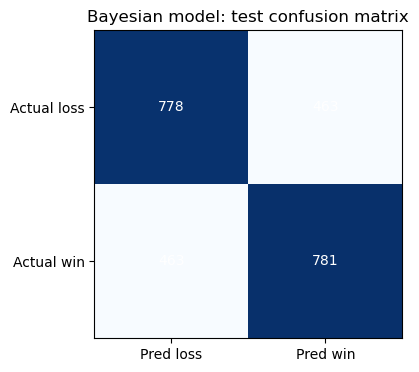

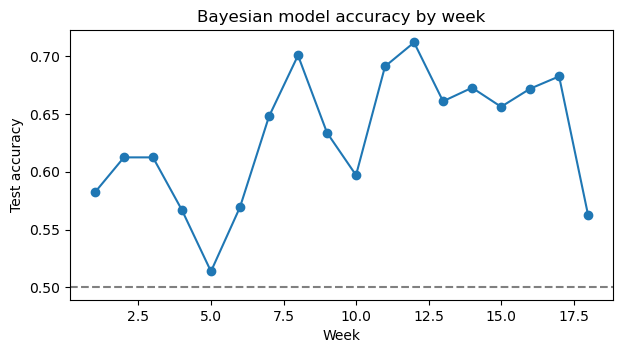

In [8]:
# Select the best-performing model and evaluate it on the test set
final_name = "Beta-Binomial head-to-head + home"
final = test_scored[final_name].copy()
final["pred"] = (final["prob"] > 0.5).astype(int)

met = classification_metrics(final["win"], final["pred"])
print(f"{final_name}: accuracy {met['accuracy']:.3f}, precision {met['precision']:.3f}, "
      f"recall {met['recall']:.3f}, F1 {met['f1']:.3f}")
plot_confusion_matrix(met["confusion_matrix"], "Bayesian model: test confusion matrix")

# Accuracy by week of the season: records are more informative later in the year
by_week = final.assign(correct=(final["pred"] == final["win"])).groupby("week")["correct"].mean()
plt.figure(figsize=(7, 3.5))
plt.plot(by_week.index, by_week.values, marker="o")
plt.axhline(0.5, color="gray", linestyle="--")
plt.xlabel("Week")
plt.ylabel("Test accuracy")
plt.title("Bayesian model accuracy by week")
plt.show()

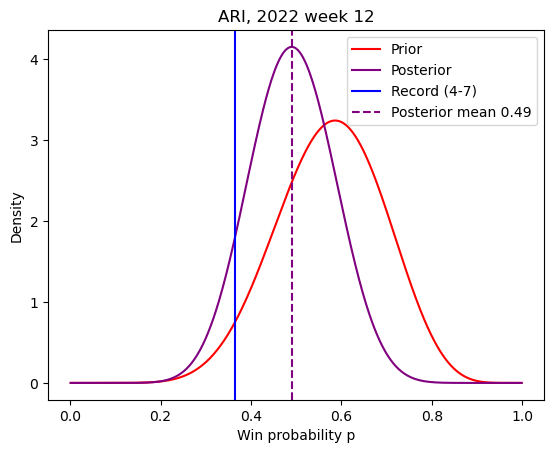

In [9]:
# Visualize the prior and posterior distributions for a single team-game, using the best hyperparameters
def beta_pdf(p, alpha, beta):
    log_norm = lgamma(alpha + beta) - lgamma(alpha) - lgamma(beta)
    return np.exp(log_norm + (alpha - 1) * np.log(p) + (beta - 1) * np.log(1 - p))


# Pick a mid/late-season test game so the record is informative
example = test[test["week"] == 12].iloc[0]
row = series[(series["game_id"] == example["game_id"]) & (series["team"] == example["team"])].iloc[0]

w, g = row["season_wins_before"], row["season_games_before"]
pw, pl = row["prev_wins"], row["prev_games"] - row["prev_wins"]

prior_alpha, prior_beta = best_a + best_carry * pw, best_a + best_carry * pl
post_alpha, post_beta = prior_alpha + w, prior_beta + (g - w)

grid = np.linspace(0.001, 0.999, 500)
mle = w / g if g > 0 else 0.5
post_mean = post_alpha / (post_alpha + post_beta)

plt.plot(grid, beta_pdf(grid, prior_alpha, prior_beta), label="Prior", color="red")
plt.plot(grid, beta_pdf(grid, post_alpha, post_beta), label="Posterior", color="purple")
plt.axvline(mle, color="blue", label=f"Record ({int(w)}-{int(g - w)})")
plt.axvline(post_mean, color="purple", linestyle="--", label=f"Posterior mean {post_mean:.2f}")
plt.xlabel("Win probability p")
plt.ylabel("Density")
plt.title(f"{row['team']}, {int(row['season'])} week {int(row['week'])}")
plt.legend()
plt.show()

In [10]:
# Save predictions for the model comparison notebook
out = final[["game_id", "team", "season", "week", "win", "prob", "pred"]]
out.to_csv(DATA_DIR / "predictions_bayes.csv", index=False)
print("Saved:", DATA_DIR / "predictions_bayes.csv", out.shape)

Saved: ../Data/data/processed/predictions_bayes.csv (2485, 7)
